In [1]:
import requests
import pandas as pd
import numpy as np
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
import matplotlib.pyplot as plt
retry_strategy = Retry(
    total=5,
    backoff_factor=1,
    status_forcelist=[429, 500, 502, 503, 504],
    allowed_methods=["GET"]
)

session = requests.Session()
session.mount("https://", HTTPAdapter(max_retries=retry_strategy))
url="https://raw.githubusercontent.com/hudl/open-data/master/data/competitions.json"
response=session.get(url,timeout=30)
print(response.status_code)

200


In [2]:
print(type(response.text))
print(response.text[:200])

<class 'str'>
[ {
  "competition_id" : 9,
  "season_id" : 281,
  "country_name" : "Germany",
  "competition_name" : "1. Bundesliga",
  "competition_gender" : "male",
  "competition_youth" : false,
  "competition_in


In [3]:
competitions=response.json()
print(type(competitions))
print(len(competitions))
print(competitions[0])

<class 'list'>
80
{'competition_id': 9, 'season_id': 281, 'country_name': 'Germany', 'competition_name': '1. Bundesliga', 'competition_gender': 'male', 'competition_youth': False, 'competition_international': False, 'season_name': '2023/2024', 'match_updated': '2024-09-28T20:46:38.893391', 'match_updated_360': '2025-11-15T23:17:41.827093', 'match_available_360': '2025-11-15T23:17:41.827093', 'match_available': '2024-09-28T20:46:38.893391'}


In [4]:
for competition in competitions[:10]:
    print(competition["competition_name"],"-",competition["season_name"])

1. Bundesliga - 2023/2024
1. Bundesliga - 2015/2016
African Cup of Nations - 2023
Champions League - 2018/2019
Champions League - 2017/2018
Champions League - 2016/2017
Champions League - 2015/2016
Champions League - 2014/2015
Champions League - 2013/2014
Champions League - 2012/2013


In [5]:
unique_competitions=set()
for competition in competitions:
    unique_competitions.add(competition["competition_name"])
print("Unique competitions:",len(unique_competitions))
print(sorted(unique_competitions))

Unique competitions: 24
['1. Bundesliga', 'African Cup of Nations', 'Champions League', 'Copa America', 'Copa del Rey', "FA Women's Super League", 'FIFA U20 World Cup', 'FIFA World Cup', 'Frauen Bundesliga', 'Indian Super league', 'La Liga', 'Liga F', 'Liga Profesional', 'Ligue 1', 'Major League Soccer', 'NWSL', 'North American League', 'Premier League', 'Serie A', 'Serie A Women', 'UEFA Euro', 'UEFA Europa League', "UEFA Women's Euro", "Women's World Cup"]


In [6]:
for competition in competitions:
    if competition["competition_name"]=="Premier League":
         print(
            competition["season_name"],
            "| Competition ID:", competition["competition_id"],
            "| Season ID:", competition["season_id"]
        )

2015/2016 | Competition ID: 2 | Season ID: 27
2003/2004 | Competition ID: 2 | Season ID: 44


In [7]:
matches_url="https://raw.githubusercontent.com/hudl/open-data/master/data/matches/2/27.json"
matches_response=requests.get(matches_url,timeout=30)
print(matches_response.status_code)

200


In [8]:
matches=matches_response.json()
print(type(matches))
print("Number of matches:",len(matches))
print(matches[0].keys())

<class 'list'>
Number of matches: 380
dict_keys(['match_id', 'match_date', 'kick_off', 'competition', 'season', 'home_team', 'away_team', 'home_score', 'away_score', 'match_status', 'match_status_360', 'last_updated', 'last_updated_360', 'metadata', 'match_week', 'competition_stage', 'stadium', 'referee'])


In [9]:
print(matches[0]["match_date"])
print(matches[0]["home_team"]["home_team_name"])
print(matches[0]["away_team"]["away_team_name"])
print(matches[0]["match_id"])

2015-09-19
Chelsea
Arsenal
3754217


In [10]:
match_id=matches[0]["match_id"]
events_url=f"https://raw.githubusercontent.com/hudl/open-data/master/data/events/{match_id}.json"
events_response=requests.get(events_url,timeout=30)
print(events_response.status_code)


200


In [11]:
events=events_response.json()
print(type(events))
print("Number of events:",len(events))
print(events[0].keys())

<class 'list'>
Number of events: 3732
dict_keys(['id', 'index', 'period', 'timestamp', 'minute', 'second', 'type', 'possession', 'possession_team', 'play_pattern', 'team', 'duration', 'tactics'])


In [12]:
event_types=set()
for event in events:
    event_types.add(event["type"]["name"])
print(sorted(event_types))

['Bad Behaviour', 'Ball Receipt*', 'Ball Recovery', 'Block', 'Carry', 'Clearance', 'Dispossessed', 'Dribble', 'Dribbled Past', 'Duel', 'Error', 'Foul Committed', 'Foul Won', 'Goal Keeper', 'Half End', 'Half Start', 'Injury Stoppage', 'Interception', 'Miscontrol', 'Own Goal Against', 'Own Goal For', 'Pass', 'Player Off', 'Player On', 'Pressure', 'Referee Ball-Drop', 'Shield', 'Shot', 'Starting XI', 'Substitution', 'Tactical Shift']


In [13]:
shots=[]
for event in events:
    if event["type"]["name"]=="Shot":
        shots.append(event)
print("Number of shots:",len(shots))
print(shots[0].keys())


Number of shots: 33
dict_keys(['id', 'index', 'period', 'timestamp', 'minute', 'second', 'type', 'possession', 'possession_team', 'play_pattern', 'team', 'player', 'position', 'location', 'duration', 'related_events', 'shot'])


In [14]:
print(shots[0]["shot"].keys())


dict_keys(['statsbomb_xg', 'end_location', 'first_time', 'technique', 'body_part', 'type', 'outcome', 'freeze_frame'])


In [15]:
shot=shots[0]
print("Player:",shot["player"]["name"])
print("Location:",shot["location"])
print("StatsBomb xG:",shot["shot"]["statsbomb_xg"])
print("Outcome:",shot["shot"]["outcome"]["name"])

Player: Aaron Ramsey
Location: [94.5, 42.9]
StatsBomb xG: 0.0388317
Outcome: Blocked


In [16]:
goal=shot["shot"]["outcome"]["name"]=="Goal"
print("Goal label:",goal)

Goal label: False


In [17]:
shot_row={
    "x":shot["location"][0],
    "y":shot["location"][1],
    "body_part":shot["shot"]["body_part"]["name"],
    "shot_type":shot["shot"]["type"]["name"],
    "goal":shot["shot"]["outcome"]["name"]=="Goal"
}
print(shot_row)

{'x': 94.5, 'y': 42.9, 'body_part': 'Left Foot', 'shot_type': 'Open Play', 'goal': False}


In [18]:
shot_rows=[]
for event in events:
    if event["type"]["name"]=="Shot":
        shot_rows.append({
            "x":event["location"][0],
            "y":event["location"][1],
            "body_part":event["shot"]["body_part"]["name"],
            "shot_type":event["shot"]["type"]["name"],
            "goal":event["shot"]["outcome"]["name"]=="Goal"

        })
print("Total shot rows:",len(shot_rows))
print(shot_rows[0])

Total shot rows: 33
{'x': 94.5, 'y': 42.9, 'body_part': 'Left Foot', 'shot_type': 'Open Play', 'goal': False}


In [19]:

shots_df=pd.DataFrame(shot_rows)
print(shots_df.shape)
print(shots_df.head())

(33, 5)
       x     y   body_part  shot_type   goal
0   94.5  42.9   Left Foot  Open Play  False
1   93.5  48.4  Right Foot  Open Play  False
2   89.8  22.3  Right Foot  Open Play  False
3   98.2  26.0  Right Foot  Open Play  False
4  105.7  24.2  Right Foot  Open Play  False


In [20]:
total_shots=0
for match in matches[:10]:
    match_id=match["match_id"]
    events_url=f"https://raw.githubusercontent.com/hudl/open-data/master/data/events/{match_id}.json"

    response=requests.get(events_url,timeout=30)
    if response.status_code==200:
        match_events=response.json()
        for event in match_events:
            if event["type"]["name"]=="Shot":
                total_shots+=1
print("Shots across 10 matches:",total_shots)
    


Shots across 10 matches: 260


In [21]:
dataset_rows=[]
failed_matches=[]
for match in matches:
    match_id=match["match_id"]
    event_url=f"https://raw.githubusercontent.com/hudl/open-data/master/data/events/{match_id}.json"
    response=session.get(event_url,timeout=30)


    if response.status_code==200:
        match_events=response.json()

        for event in match_events:
            
            if event["type"]["name"]=="Shot":
                dataset_rows.append({
                    "match_id":match_id,
                    "x":event["location"][0],
                    "y":event["location"][1],
                    "body_part":event["shot"]["body_part"]["name"],
                    "shot_type":event["shot"]["type"]["name"],
                    "goal":event["shot"]["outcome"]["name"]=="Goal",
                    "freeze_frame":event["shot"].get("freeze_frame")
                })
    else:
          failed_matches.append((match_id,response.status_code))

print("Total matches:",len(matches))
print("Total shots:",len(dataset_rows))
print("Total goals:",sum(row["goal"] for row in dataset_rows))
print("Failed matches:",len(failed_matches))


Total matches: 380
Total shots: 9908
Total goals: 988
Failed matches: 0


In [22]:
shots_df=pd.DataFrame(dataset_rows)

print("Dataset shape:",shots_df.shape)
print("\nMissing values:")
print(shots_df.isna().sum())


Dataset shape: (9908, 7)

Missing values:
match_id         0
x                0
y                0
body_part        0
shot_type        0
goal             0
freeze_frame    73
dtype: int64


In [23]:
print(shots_df["goal"].value_counts())
print(shots_df["goal"].value_counts(normalize=True)*100) 


goal
False    8920
True      988
Name: count, dtype: int64
goal
False    90.02826
True      9.97174
Name: proportion, dtype: float64


In [24]:

shots_df["distance_to_goal"] = np.sqrt(
    (120 - shots_df["x"])**2
    + (40 - shots_df["y"])**2
)


v1_x = 120 - shots_df["x"]
v1_y = 36 - shots_df["y"]

v2_x = 120 - shots_df["x"]
v2_y = 44 - shots_df["y"]


cross = v1_x * v2_y - v1_y * v2_x
dot = v1_x * v2_x + v1_y * v2_y


shots_df["shot_angle"] = np.arctan2(
    np.abs(cross),
    dot
)

print(
    shots_df[
        ["distance_to_goal", "shot_angle"]
    ].head()
)

   distance_to_goal  shot_angle
0         25.664372    0.307371
1         27.799460    0.273123
2         35.004714    0.197184
3         25.908300    0.260131
4         21.310326    0.255407


In [26]:
print(shots_df.sort_values("shot_angle",ascending=False).head())

      match_id      x     y   body_part  shot_type  goal  \
3733   3754276  119.3  40.6  Right Foot  Open Play  True   
2514   3754167  119.2  41.9  Right Foot  Open Play  True   
2767   3754211  118.9  40.3  Right Foot  Open Play  True   
3215   3754230  119.3  37.5  Right Foot  Open Play  True   
2007   3754112  118.8  41.3       Other  Open Play  True   

                                           freeze_frame  distance_to_goal  \
3733  [{'location': [119.5, 39.8], 'player': {'id': ...          0.921954   
2514  [{'location': [113.3, 47.7], 'player': {'id': ...          2.061553   
2767  [{'location': [119.5, 52.8], 'player': {'id': ...          1.140175   
3215  [{'location': [99.8, 36.8], 'player': {'id': 3...          2.596151   
2007  [{'location': [119.1, 39.2], 'player': {'id': ...          1.769181   

      shot_angle  
3733    2.787532  
2514    2.642842  
2767    2.602174  
3215    2.597687  
2007    2.500707  


In [27]:
print(shots_df["body_part"].value_counts())
print(shots_df["shot_type"].value_counts())


body_part
Right Foot    5367
Left Foot     2916
Head          1608
Other           17
Name: count, dtype: int64
shot_type
Open Play    9415
Free Kick     401
Penalty        91
Corner          1
Name: count, dtype: int64


In [28]:
shots_df.to_csv("shots_2015_16.csv",index=False)


In [29]:
X=shots_df[["distance_to_goal","shot_angle","body_part","shot_type"]]
y=shots_df["goal"]

print("X shape:",X.shape)
print("y shape:",y.shape)


X shape: (9908, 4)
y shape: (9908,)


In [30]:
from sklearn.model_selection import GroupShuffleSplit
group_split=GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx,test_idx=next(
    group_split.split(X,y,groups=shots_df["match_id"])
)

In [31]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
numerical_features=["distance_to_goal","shot_angle"]
categorical_features=["body_part","shot_type"]
preprocessor=ColumnTransformer(
    transformers=[
        ("num",StandardScaler(),numerical_features),
        ("cat",OneHotEncoder(handle_unknown="ignore"),categorical_features)
    ]
)

In [32]:
X_train=X.iloc[train_idx]
X_test=X.iloc[test_idx]
y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

X_train_prepared=preprocessor.fit_transform(X_train)
X_test_prepared=preprocessor.transform(X_test)

print("Training shape:", X_train_prepared.shape)
print("Testing shape:", X_test_prepared.shape)

Training shape: (7882, 10)
Testing shape: (2026, 10)


In [33]:
from sklearn.linear_model import LogisticRegression
model=LogisticRegression(max_iter=1000,random_state=42)
model.fit(X_train_prepared,y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [34]:
y_pred_proba=model.predict_proba(X_test_prepared)[:,1]
print(y_pred_proba[:10])

[0.09446571 0.127357   0.19023791 0.31255178 0.07449101 0.06023945
 0.06532907 0.08424094 0.07728542 0.19394584]


In [35]:
from sklearn.metrics import roc_auc_score,brier_score_loss,log_loss
print("ROC-AUC:", roc_auc_score(y_test, y_pred_proba))
print("Brier Score:", brier_score_loss(y_test, y_pred_proba))
print("Log Loss:", log_loss(y_test, y_pred_proba))

ROC-AUC: 0.7591347450335802
Brier Score: 0.08062557298233274
Log Loss: 0.2852288909432482


In [36]:
baseline_prob=y_train.mean()
baseline_predictions=np.full(
    len(y_test),
    baseline_prob
)
print("Baseline probability:", baseline_prob)
print("Baseline Brier Score:",
      brier_score_loss(y_test, baseline_predictions))

print("Baseline Log Loss:",
      log_loss(y_test, baseline_predictions))

Baseline probability: 0.09807155544278102
Baseline Brier Score: 0.09492367221776811
Baseline Log Loss: 0.3386841247615682


In [37]:
brier_skill_score=1-(
    brier_score_loss(y_test,y_pred_proba)/
    brier_score_loss(y_test,baseline_predictions)
)
print(brier_skill_score)


0.15062732932027267


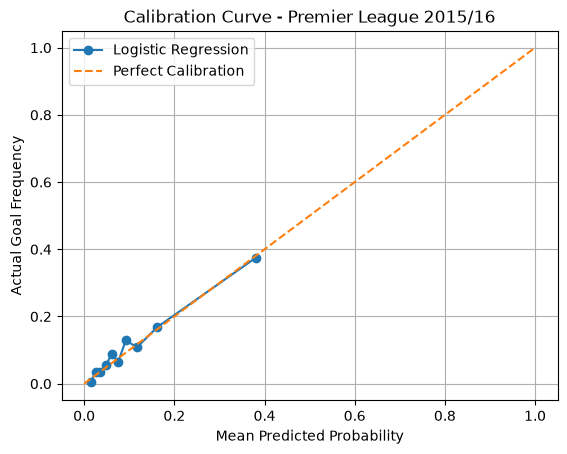

In [38]:
from sklearn.calibration import calibration_curve
prob_true,prob_pred=calibration_curve(
    y_test,
    y_pred_proba,
    n_bins=10,
    strategy="quantile"
)

plt.plot(prob_pred,prob_true,marker="o",label="Logistic Regression")
plt.plot([0,1],[0,1],linestyle="--",label="Perfect Calibration")
plt.xlabel("Mean Predicted Probability")
plt.ylabel("Actual Goal Frequency")
plt.title("Calibration Curve - Premier League 2015/16")

plt.legend()
plt.grid()
plt.show()

In [39]:
calibration_result=pd.DataFrame({
    "prediction_probabilty":prob_pred,
    "actual_goal_frequency":prob_true
})
print(calibration_result.round(4))

   prediction_probabilty  actual_goal_frequency
0                 0.0143                 0.0049
1                 0.0253                 0.0345
2                 0.0362                 0.0347
3                 0.0483                 0.0542
4                 0.0609                 0.0891
5                 0.0751                 0.0640
6                 0.0923                 0.1287
7                 0.1174                 0.1084
8                 0.1619                 0.1683
9                 0.3801                 0.3744


In [40]:
for shot_event in shots[:5]:
    print(
        "First time:",shot_event["shot"].get("first_time"),
        "Technique:",shot_event["shot"]["technique"]["name"]
    )

First time: True Technique: Normal
First time: None Technique: Normal
First time: None Technique: Normal
First time: None Technique: Normal
First time: None Technique: Normal


In [41]:
freeze_frame=shots[0]["shot"]["freeze_frame"]

print(freeze_frame[0])
print(freeze_frame[0].keys())

{'location': [107.2, 45.2], 'player': {'id': 3957, 'name': 'César Azpilicueta Tanco'}, 'position': {'id': 6, 'name': 'Left Back'}, 'teammate': False}
dict_keys(['location', 'player', 'position', 'teammate'])


In [42]:
opponents=[
    player for player in freeze_frame
    if not player["teammate"]
]
print("Opposition players:",len(opponents))

for player in opponents:
    print(player["position"]["name"],player["location"])

Opposition players: 10
Left Back [107.2, 45.2]
Left Defensive Midfield [97.5, 43.8]
Right Wing [100.9, 36.9]
Left Center Back [108.8, 30.3]
Right Center Back [113.3, 41.9]
Center Attacking Midfield [113.7, 24.1]
Right Back [104.0, 35.8]
Center Forward [107.3, 31.5]
Right Defensive Midfield [98.8, 21.6]
Goalkeeper [118.7, 39.7]


In [43]:
shots_with_freeze_frame=[
    shot for shot in shots
    if shot["shot"].get("freeze_frame")
]
print("Total shots:",len(shots))
print("Shots with freeze frames:",len(shots_with_freeze_frame))
print("Shots without freese frames:",
      len(shots)-len(shots_with_freeze_frame))

Total shots: 33
Shots with freeze frames: 33
Shots without freese frames: 0


In [44]:


total_shots = len(dataset_rows)

shots_with_frames = sum(
    bool(row.get("freeze_frame"))
    for row in dataset_rows
)

missing_frames = total_shots - shots_with_frames

coverage = (
    shots_with_frames / total_shots * 100
    if total_shots > 0 else 0
)

print("Matches in schedule:", len(matches))
print("Failed matches:", len(failed_matches))
print("Total shots:", total_shots)
print("Shots with freeze frames:", shots_with_frames)
print("Shots without freeze frames:", missing_frames)
print("Coverage:", round(coverage, 2), "%")

Matches in schedule: 380
Failed matches: 0
Total shots: 9908
Shots with freeze frames: 9835
Shots without freeze frames: 73
Coverage: 99.26 %


In [45]:
print(dataset_rows[0].keys())

shots_with_frame = sum(
    bool(row["freeze_frame"])
    for row in dataset_rows
)

print("Shots with freeze frames:", shots_with_frame)

dict_keys(['match_id', 'x', 'y', 'body_part', 'shot_type', 'goal', 'freeze_frame'])
Shots with freeze frames: 9835


In [46]:
shots_df_with_frames = pd.DataFrame(dataset_rows)

valid_frames = shots_df_with_frames[
    shots_df_with_frames["freeze_frame"].map(bool)
]

print("Dataset shape:", shots_df_with_frames.shape)
print("Shots with usable frames:", len(valid_frames))

sample_frame = valid_frames.iloc[0]["freeze_frame"]

print("\nPlayers in sample freeze frame:", len(sample_frame))
print("\nFirst two players:")
print(sample_frame[:2])

Dataset shape: (9908, 7)
Shots with usable frames: 9835

Players in sample freeze frame: 16

First two players:
[{'location': [107.2, 45.2], 'player': {'id': 3957, 'name': 'César Azpilicueta Tanco'}, 'position': {'id': 6, 'name': 'Left Back'}, 'teammate': False}, {'location': [97.5, 43.8], 'player': {'id': 3381, 'name': 'Nemanja Matić'}, 'position': {'id': 11, 'name': 'Left Defensive Midfield'}, 'teammate': False}]


In [47]:
sample_frame=valid_frames.iloc[0]["freeze_frame"]
teammates=[
    player for player in sample_frame
    if player["teammate"]
]

opponents=[
    player for player in sample_frame
    if not player["teammate"]
]

goalkeepers=[
    player for player in sample_frame
    if player["position"]["name"]=="Goalkeeper"
]

opposition_outfield=[
    player for player in opponents
    if player["position"]["name"]!="Goalkeeper"
]

print("Attacking teammates:", len(teammates))
print("Opposition players:", len(opponents))
print("Opposition outfield players:", len(opposition_outfield))
print("Goalkeepers:", len(goalkeepers))

print("\nGoalkeeper details:")
for goalkeeper in goalkeepers:
    print(goalkeeper["location"], goalkeeper["teammate"])

Attacking teammates: 6
Opposition players: 10
Opposition outfield players: 9
Goalkeepers: 1

Goalkeeper details:
[118.7, 39.7] False


In [48]:
opposition_outfield=[
    player for player in sample_frame
    if player["position"]["name"]!="Goalkeeper" and not player["teammate"]
]

print("Opposition outfield players:", len(opposition_outfield))

for player in opposition_outfield:
    print(player["position"]["name"], player["location"])

Opposition outfield players: 9
Left Back [107.2, 45.2]
Left Defensive Midfield [97.5, 43.8]
Right Wing [100.9, 36.9]
Left Center Back [108.8, 30.3]
Right Center Back [113.3, 41.9]
Center Attacking Midfield [113.7, 24.1]
Right Back [104.0, 35.8]
Center Forward [107.3, 31.5]
Right Defensive Midfield [98.8, 21.6]


In [49]:
sample_shot=valid_frames.iloc[0]
shooter_x=sample_shot["x"]
shooter_y=sample_shot["y"]

goal_x=120
goal_y=40
print("Shooter:",shooter_x,shooter_y)
print("Goal centre:",goal_x,goal_y)

Shooter: 94.5 42.9
Goal centre: 120 40


In [50]:
shooter_distance=np.sqrt((shooter_x-goal_x)**2+(shooter_y-goal_y)**2)
print(shooter_distance)
for defender in opposition_outfield:
    defender_x,defender_y=defender["location"]
print(defender_x,defender_y)

25.664372191814863
98.8 21.6


In [51]:
defender_offset_x=(defender_x-shooter_x)
defender_offset_y=(defender_y-shooter_y)
print(defender_offset_x,defender_offset_y)
area_defe=(goal_x-shooter_x)*(defender_offset_y)-(goal_y-shooter_y)*(defender_offset_x)
print(area_defe)
perp_dist=abs(area_defe)/shooter_distance
print(perp_dist)
dot_pro=(goal_x-shooter_x)*(defender_offset_x)+(goal_y-shooter_y)*(defender_offset_y)
print(dot_pro)

p=dot_pro/shooter_distance
print(p)


4.299999999999997 -21.299999999999997
-530.68
20.677692640743796
171.41999999999987
6.679298395410227


In [52]:
lane_threshold=2/3
central_lane_blockers=0

for defender in opposition_outfield:
    defender_x,defender_y=defender["location"]
    print(defender_x,defender_y)
    defender_offset_x=defender_x-shooter_x
    defender_offset_y=defender_y-shooter_y
    print(defender_offset_x,defender_offset_y)
    area_defe=(goal_x-shooter_x)*(defender_offset_y)-(goal_y-shooter_y)*(defender_offset_x)
    print(area_defe)
    perp_dist=abs(area_defe)/shooter_distance
    print("Perpendicular distance:", perp_dist)
    dot_pro=(goal_x-shooter_x)*(defender_offset_x)+(goal_y-shooter_y)*(defender_offset_y)
    print(dot_pro)
    

    projection_distance = dot_pro / shooter_distance

    if 0 < projection_distance < shooter_distance and perp_dist <= lane_threshold:
        central_lane_blockers+=1
    
    print("Central lane blockers:",central_lane_blockers)







107.2 45.2
12.700000000000003 2.3000000000000043
95.4800000000001
Perpendicular distance: 3.720332579592636
317.18000000000006
Central lane blockers: 0
97.5 43.8
3.0 0.8999999999999986
31.64999999999996
Perpendicular distance: 1.233227127608993
73.89
Central lane blockers: 0
100.9 36.9
6.400000000000006 -6.0
-134.44
Perpendicular distance: 5.238390364478775
180.60000000000014
Central lane blockers: 0
108.8 30.3
14.299999999999997 -12.599999999999998
-279.83
Perpendicular distance: 10.903442247040282
401.1899999999999
Central lane blockers: 0
113.3 41.9
18.799999999999997 -1.0
29.019999999999968
Perpendicular distance: 1.1307504342247388
482.2999999999999
Central lane blockers: 0
113.7 24.1
19.200000000000003 -18.799999999999997
-423.7199999999999
Perpendicular distance: 16.510047346302784
544.12
Central lane blockers: 0
104.0 35.8
9.5 -7.100000000000001
-153.50000000000006
Perpendicular distance: 5.981054157598128
262.84
Central lane blockers: 0
107.3 31.5
12.799999999999997 -11.399999

In [53]:
m1=(36-shooter_y)/(goal_x-shooter_x)
m2=(44-shooter_y)/(goal_x-shooter_x)
print(m1,m2)
lower_y = shooter_y + m1 * (defender_x - shooter_x)
upper_y = shooter_y + m2 * (defender_x - shooter_x)

-0.2705882352941176 0.04313725490196084


In [54]:
goal_mouth_triangle_blocker=0
for defender in opposition_outfield:
    defender_x,defender_y=defender["location"]
   
    lower_y=shooter_y+m1*(defender_x-shooter_x)
    upper_y=shooter_y+m2*(defender_x-shooter_x)
    if shooter_x<=defender_x<=goal_x and lower_y<=defender_y<=upper_y:
        goal_mouth_triangle_blocker+=1

print("goal_mouth_triangle_blocker:",goal_mouth_triangle_blocker)
    


goal_mouth_triangle_blocker: 1


In [55]:
def count_triangle_blockers(
    shooter_x,
    shooter_y,
    freeze_frame,
    left_post,
    right_post
):

    if not freeze_frame:
        return np.nan

    left_x, left_y = left_post
    right_x, right_y = right_post

  
    if left_x != right_x:
        raise ValueError("Goalposts must share the same x-coordinate.")

    goal_x = left_x

  
    if left_x == shooter_x:
        return np.nan

    blocker_count = 0

    for player in freeze_frame:

     
        if (
            player["teammate"]
            or player["position"]["name"] == "Goalkeeper"
        ):
            continue

        defender_x, defender_y = player["location"]

     
        if not min(shooter_x, goal_x) <= defender_x <= max(shooter_x, goal_x):
            continue

        y1 = shooter_y + (left_y - shooter_y) * (
            (defender_x - shooter_x) / (left_x - shooter_x)
        )

      
        y2 = shooter_y + (right_y - shooter_y) * (
            (defender_x - shooter_x) / (right_x - shooter_x)
        )

        if min(y1, y2) <= defender_y <= max(y1, y2):
            blocker_count += 1

    return blocker_count


In [56]:
sample_shot = valid_frames.iloc[0]

triangle_count = count_triangle_blockers(
    sample_shot["x"],
    sample_shot["y"],
    sample_shot["freeze_frame"],
    (120, 36),
    (120, 44)
)

print("Goal-mouth triangle blockers:", triangle_count)

Goal-mouth triangle blockers: 1


In [57]:
shots_df_with_frames["goal_mouth_triangle_blockers"]=shots_df_with_frames.apply(
    lambda row:count_triangle_blockers(
        row["x"],
        row["y"],
        row["freeze_frame"],
        (120, 36),
        (120, 44)
    ),
    axis=1
)
print(shots_df_with_frames.columns.tolist())

print(
    shots_df_with_frames["goal_mouth_triangle_blockers"].value_counts(
        dropna=False
    ).sort_index()
)

['match_id', 'x', 'y', 'body_part', 'shot_type', 'goal', 'freeze_frame', 'goal_mouth_triangle_blockers']
goal_mouth_triangle_blockers
0.0    4558
1.0    3499
2.0    1117
3.0     422
4.0     182
5.0      46
6.0       9
7.0       1
8.0       1
NaN      73
Name: count, dtype: int64


In [58]:
print(shots_df_with_frames[
    "goal_mouth_triangle_blockers"
].describe())

print("\nMissing values:")
print(shots_df_with_frames[
    "goal_mouth_triangle_blockers"
].isna().sum())

print("\nBlocker count distribution:")
print(shots_df_with_frames[
    "goal_mouth_triangle_blockers"
].value_counts().sort_index())

count    9835.000000
mean        0.816065
std         0.993893
min         0.000000
25%         0.000000
50%         1.000000
75%         1.000000
max         8.000000
Name: goal_mouth_triangle_blockers, dtype: float64

Missing values:
73

Blocker count distribution:
goal_mouth_triangle_blockers
0.0    4558
1.0    3499
2.0    1117
3.0     422
4.0     182
5.0      46
6.0       9
7.0       1
8.0       1
Name: count, dtype: int64


In [59]:
assert "goal_mouth_triangle_blockers" in shots_df_with_frames.columns

print("Triangle-blocker feature verified.")

print(
    "Missing values:",
    shots_df_with_frames["goal_mouth_triangle_blockers"].isna().sum()
)

Triangle-blocker feature verified.
Missing values: 73


In [60]:
def count_central_lane_blockers(
    shooter_x,
    shooter_y,
    freeze_frame,
    goal_x,
    goal_y,
    lane_threshold=2/3
):
    if not freeze_frame:
        return None

    dx = goal_x - shooter_x
    dy = goal_y - shooter_y

    shooter_distance = np.sqrt(dx**2 + dy**2)

    if shooter_distance == 0:
        return None

    blocker_count = 0

    for player in freeze_frame:

        if player["teammate"] or player["position"]["name"] == "Goalkeeper":
            continue

        defender_x, defender_y = player["location"]

        offset_x = defender_x - shooter_x
        offset_y = defender_y - shooter_y

        cross_product = abs(dx * offset_y - dy * offset_x)

        perp_dist = cross_product / shooter_distance

        dot_product = dx * offset_x + dy * offset_y

        projection_distance = dot_product / shooter_distance

        if (0 < projection_distance < shooter_distance
                and perp_dist <= lane_threshold):
            blocker_count += 1

    return blocker_count

In [61]:
shots_df_with_frames["central_lane_blockers"]=shots_df_with_frames.apply(
    lambda row:count_central_lane_blockers(
        row["x"],
        row["y"],
        row["freeze_frame"],
        120,
        40
    ),
    axis=1
)

for feature in[
    "central_lane_blockers",
    "goal_mouth_triangle_blockers"
]:
    print(f"\n{feature}")
    print(shots_df_with_frames[feature].value_counts(
        dropna=False
    ).sort_index())


central_lane_blockers
central_lane_blockers
0.0    4688
1.0    4232
2.0     823
3.0      82
4.0       9
5.0       1
NaN      73
Name: count, dtype: int64

goal_mouth_triangle_blockers
goal_mouth_triangle_blockers
0.0    4558
1.0    3499
2.0    1117
3.0     422
4.0     182
5.0      46
6.0       9
7.0       1
8.0       1
NaN      73
Name: count, dtype: int64


In [62]:
goalkeepers = [
    player for player in sample_frame
    if player["position"]["name"] == "Goalkeeper"
    and not player["teammate"]
]

print("Goalkeepers:", len(goalkeepers))

for goalkeeper in goalkeepers:
    print("Location:", goalkeeper["location"])

Goalkeepers: 1
Location: [118.7, 39.7]


In [63]:
def get_goalkeeper_features(
    shooter_x,
    shooter_y,
    freeze_frame,
    goal_x=120,
    goal_y=40
):

    if not freeze_frame:
        return np.nan, np.nan

   
    goalkeeper_candidates = [
        player for player in freeze_frame
        if not player["teammate"]
        and player["position"]["name"] == "Goalkeeper"
    ]

    if not goalkeeper_candidates:
        return np.nan, np.nan

   
    goalkeeper_x, goalkeeper_y = goalkeeper_candidates[0]["location"]


    dx = goal_x - shooter_x
    dy = goal_y - shooter_y

   
    offset_x = goalkeeper_x - shooter_x
    offset_y = goalkeeper_y - shooter_y

  
    shooter_distance = np.sqrt(dx**2 + dy**2)

    goalkeeper_distance = np.sqrt(
        offset_x**2 + offset_y**2
    )

    if shooter_distance == 0 or goalkeeper_distance == 0:
        return np.nan, np.nan

    dot_gk = dx * offset_x + dy * offset_y


    cross_gk = dx * offset_y - dy * offset_x

   
    goalkeeper_angle = np.degrees(
        np.arctan2(abs(cross_gk), dot_gk)
    )

    return goalkeeper_distance, goalkeeper_angle




In [78]:


has_frame = shots_df_with_frames["freeze_frame"].apply(
    lambda ff: isinstance(ff, list) and len(ff) > 0
)

has_opponent_gk = shots_df_with_frames["freeze_frame"].apply(
    lambda ff: (
        isinstance(ff, list)
        and any(
            not player["teammate"]
            and player["position"]["name"] == "Goalkeeper"
            for player in ff
        )
    )
)

print("Shots without frames:", (~has_frame).sum())

print(
    "Shots with frames but no opposition goalkeeper:",
    (has_frame & ~has_opponent_gk).sum()
)

print("Shots with an identifiable goalkeeper:", has_opponent_gk.sum())

Shots without frames: 73
Shots with frames but no opposition goalkeeper: 13
Shots with an identifiable goalkeeper: 9822


In [79]:


missing_gk_mask = has_frame & ~has_opponent_gk

missing_gk_rows = shots_df_with_frames.loc[missing_gk_mask]

for idx, row in missing_gk_rows.iterrows():

    frame = row["freeze_frame"]

    goalkeeper_entries = [
        player for player in frame
        if "goalkeeper" in player["position"]["name"].lower()
    ]

    print(f"\nShot index: {idx}")
    print("Match ID:", row["match_id"])
    print("Players in frame:", len(frame))
    print("Goalkeeper entries:", goalkeeper_entries)

    if not goalkeeper_entries:
        print("No goalkeeper position recorded in this frame.")


Shot index: 629
Match ID: 3754014
Players in frame: 9
Goalkeeper entries: [{'location': [115.7, 48.2], 'player': {'id': 3537, 'name': 'Jack Butland'}, 'position': {'id': 1, 'name': 'Goalkeeper'}, 'teammate': True}]

Shot index: 903
Match ID: 3753978
Players in frame: 16
Goalkeeper entries: [{'location': [118.0, 39.8], 'player': {'id': 3262, 'name': 'Łukasz Fabiański'}, 'position': {'id': 1, 'name': 'Goalkeeper'}, 'teammate': True}]

Shot index: 1821
Match ID: 3754046
Players in frame: 12
Goalkeeper entries: []
No goalkeeper position recorded in this frame.

Shot index: 2058
Match ID: 3754054
Players in frame: 14
Goalkeeper entries: []
No goalkeeper position recorded in this frame.

Shot index: 2514
Match ID: 3754167
Players in frame: 9
Goalkeeper entries: [{'location': [118.8, 39.1], 'player': {'id': 23635, 'name': 'John Ruddy'}, 'position': {'id': 1, 'name': 'Goalkeeper'}, 'teammate': True}]

Shot index: 2582
Match ID: 3754153
Players in frame: 17
Goalkeeper entries: [{'location': [1

Goalkeeper distance and angular displacement were available for 9,822 of 9,908 shots (99.13%). In 73 shots, freeze-frame data was unavailable. Another 8 frames contained only the shooting team's goalkeeper, while 5 contained no goalkeeper position. These observations were retained, with missing numerical values handled through median imputation in the preprocessing pipeline.

In [64]:
gk_features=shots_df_with_frames.apply(
    lambda row: get_goalkeeper_features(
        row["x"],
        row["y"],
        row["freeze_frame"]
    ),
    axis=1,
    result_type="expand"
)

gk_features.columns=[
    "goalkeeper_distance",
    "goalkeeper_angle"
]
shots_df_with_frames[
    ["goalkeeper_distance", "goalkeeper_angle"]
] = gk_features

shots_df_with_frames[
    ["goalkeeper_distance", "goalkeeper_angle"]
].isna().sum()

goalkeeper_distance    86
goalkeeper_angle       86
dtype: int64

In [65]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    roc_auc_score,
    brier_score_loss,
    log_loss
)

In [66]:

print("\nshots_df_with_frames columns:")
print(shots_df_with_frames.columns.tolist())


shots_df_with_frames["distance_to_goal"] = np.sqrt(
    (120 - shots_df_with_frames["x"])**2
    + (40 - shots_df_with_frames["y"])**2
)


shot_x = shots_df_with_frames["x"]
shot_y = shots_df_with_frames["y"]


v1_x = 120 - shot_x
v1_y = 36 - shot_y


v2_x = 120 - shot_x
v2_y = 44 - shot_y


cross = v1_x * v2_y - v1_y * v2_x
dot = v1_x * v2_x + v1_y * v2_y


shots_df_with_frames["shot_angle"] = np.arctan2(
    np.abs(cross),
    dot
)

print(
    shots_df_with_frames[
        ["distance_to_goal", "shot_angle"]
    ].describe()
)

print(shots_df_with_frames.columns.tolist())


shots_df_with_frames columns:
['match_id', 'x', 'y', 'body_part', 'shot_type', 'goal', 'freeze_frame', 'goal_mouth_triangle_blockers', 'central_lane_blockers', 'goalkeeper_distance', 'goalkeeper_angle']
       distance_to_goal   shot_angle
count       9908.000000  9908.000000
mean          19.071931     0.443055
std            8.291229     0.274477
min            0.921954     0.001063
25%           12.126417     0.267127
50%           18.791620     0.341150
75%           25.339840     0.539819
max           86.137100     2.787532
['match_id', 'x', 'y', 'body_part', 'shot_type', 'goal', 'freeze_frame', 'goal_mouth_triangle_blockers', 'central_lane_blockers', 'goalkeeper_distance', 'goalkeeper_angle', 'distance_to_goal', 'shot_angle']


In [80]:
base_numeric=[
    "distance_to_goal","shot_angle"
]
enhanced_numeric=base_numeric+[
    "central_lane_blockers","goal_mouth_triangle_blockers","goalkeeper_distance","goalkeeper_angle"
]
categorical_features=["body_part","shot_type"]

y=shots_df_with_frames["goal"]

X_base=shots_df_with_frames[
    base_numeric+categorical_features
]
X_enhanced=shots_df_with_frames[
    enhanced_numeric+categorical_features
]

splitter=GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx,test_idx=next(
    splitter.split(
        X_enhanced,
        y,
        groups=shots_df_with_frames["match_id"]
    )
)

def build_xg_model(numeric_features):

    numeric_pipeline=make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler()
    )

    categorical_pipeline=make_pipeline(
        SimpleImputer(strategy="most_frequent"),
        OneHotEncoder(handle_unknown="ignore")
    )

    preprocessor=ColumnTransformer([("num",numeric_pipeline,numeric_features),
    ("cat",categorical_pipeline,categorical_features)
    ])

    model=make_pipeline(
        preprocessor,
        LogisticRegression(
        max_iter=1000,
        random_state=42
    )
    )
    return model



    
     
    

In [81]:

baseline_model=build_xg_model(base_numeric)
enhanced_model=build_xg_model(enhanced_numeric)

baseline_model.fit(X_base.iloc[train_idx],
                   y.iloc[train_idx])

enhanced_model.fit(
    X_enhanced.iloc[train_idx],
    y.iloc[train_idx]
)


def evaluate_model(model,X_test,y_test):
    probabilites=model.predict_proba(X_test)[:,1]
    return{
        "ROC-AUC":roc_auc_score(y_test,probabilites),
        "Brier Score":brier_score_loss(y_test,probabilites),
        "Log Loss":log_loss(y_test,probabilites)
    }
baseline_results=evaluate_model(
    baseline_model,
    X_base.iloc[test_idx],
    y.iloc[test_idx]
)

enhanced_results=evaluate_model(
    enhanced_model,
    X_enhanced.iloc[test_idx],
    y.iloc[test_idx]
)

results=pd.DataFrame(
    [baseline_results,enhanced_results],
    index=["Baseline","Enhanced"]
)

print(results.round(5))

          ROC-AUC  Brier Score  Log Loss
Baseline  0.75913      0.08063   0.28523
Enhanced  0.77474      0.07947   0.28033


In [82]:
feature_names=enhanced_model.named_steps[
    "columntransformer"
].get_feature_names_out()

coefficients=enhanced_model.named_steps[
    "logisticregression"
].coef_[0]

coefficient_df=pd.DataFrame({
    "Feature":feature_names,
    "Coefficient":coefficients
})

coefficient_df=coefficient_df.sort_values(
    "Coefficient",
    ascending=False
)

print(coefficient_df.to_string(index=False))

                          Feature  Coefficient
           cat__shot_type_Penalty     1.449447
             cat__body_part_Other     0.765670
            cat__shot_type_Corner     0.446987
                  num__shot_angle     0.317430
            num__goalkeeper_angle     0.135273
        cat__body_part_Right Foot    -0.014065
            num__distance_to_goal    -0.045227
         cat__body_part_Left Foot    -0.144610
         cat__shot_type_Free Kick    -0.187062
num__goal_mouth_triangle_blockers    -0.189759
       num__central_lane_blockers    -0.241345
         num__goalkeeper_distance    -0.752887
              cat__body_part_Head    -0.891337
         cat__shot_type_Open Play    -1.993714


In [83]:
correlation_check = shots_df_with_frames[
    [
        "distance_to_goal",
        "goalkeeper_distance",
        "goalkeeper_angle",
        "shot_angle",
        "central_lane_blockers",
        "goal_mouth_triangle_blockers",
        "goal"
    ]
].corr()

print(correlation_check.round(3))

                              distance_to_goal  goalkeeper_distance  \
distance_to_goal                         1.000                0.965   
goalkeeper_distance                      0.965                1.000   
goalkeeper_angle                        -0.353               -0.345   
shot_angle                              -0.760               -0.682   
central_lane_blockers                    0.117                0.165   
goal_mouth_triangle_blockers             0.162                0.230   
goal                                    -0.238               -0.235   

                              goalkeeper_angle  shot_angle  \
distance_to_goal                        -0.353      -0.760   
goalkeeper_distance                     -0.345      -0.682   
goalkeeper_angle                         1.000       0.463   
shot_angle                               0.463       1.000   
central_lane_blockers                   -0.087      -0.107   
goal_mouth_triangle_blockers            -0.062      -0.074 

In [84]:
# Remove goalkeeper_distance from numerical features
enhanced_numeric_no_gk_distance = [
    feature for feature in enhanced_numeric
    if feature != "goalkeeper_distance"
]

# Create the new feature DataFrame
X_enhanced_no_gk_distance = shots_df_with_frames[
    enhanced_numeric_no_gk_distance + categorical_features
]

# Build and train the model
model_no_gk_distance = build_xg_model(
    enhanced_numeric_no_gk_distance
)

model_no_gk_distance.fit(
    X_enhanced_no_gk_distance.iloc[train_idx],
    y.iloc[train_idx]
)

# Evaluate
no_gk_distance_results = evaluate_model(
    model_no_gk_distance,
    X_enhanced_no_gk_distance.iloc[test_idx],
    y.iloc[test_idx]
)

# Compare all three models
comparison = pd.DataFrame(
    [
        baseline_results,
        enhanced_results,
        no_gk_distance_results
    ],
    index=[
        "Baseline",
        "Enhanced",
        "Enhanced without GK distance"
    ]
)

print(comparison.round(5))

                              ROC-AUC  Brier Score  Log Loss
Baseline                      0.75913      0.08063   0.28523
Enhanced                      0.77474      0.07947   0.28033
Enhanced without GK distance  0.76906      0.07964   0.28177


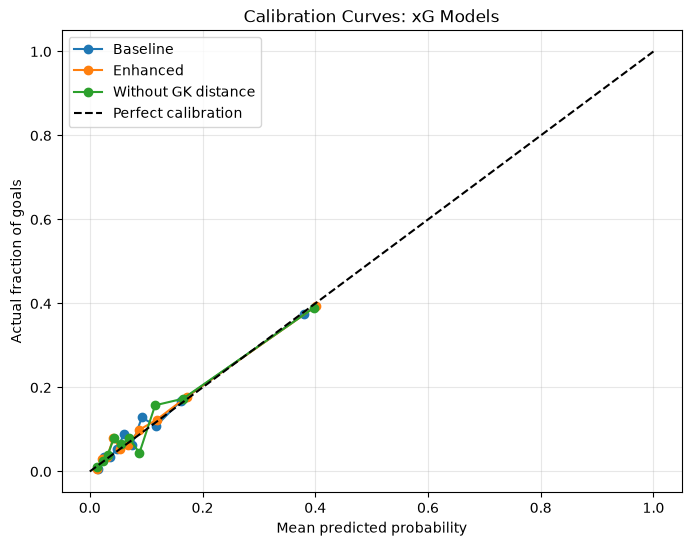

In [85]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

# Actual test outcomes
y_test = y.iloc[test_idx]

# Predicted probabilities
p_baseline = baseline_model.predict_proba(
    X_base.iloc[test_idx]
)[:, 1]

p_enhanced = enhanced_model.predict_proba(
    X_enhanced.iloc[test_idx]
)[:, 1]

p_no_gk_distance = model_no_gk_distance.predict_proba(
    X_enhanced_no_gk_distance.iloc[test_idx]
)[:, 1]

# Plot calibration curves
plt.figure(figsize=(8, 6))

for name, probabilities in [
    ("Baseline", p_baseline),
    ("Enhanced", p_enhanced),
    ("Without GK distance", p_no_gk_distance)
]:
    actual_fraction, mean_probability = calibration_curve(
        y_test,
        probabilities,
        n_bins=10,
        strategy="quantile"
    )

    plt.plot(
        mean_probability,
        actual_fraction,
        marker="o",
        label=name
    )

# Perfect calibration reference
plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="black",
    label="Perfect calibration"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Actual fraction of goals")
plt.title("Calibration Curves: xG Models")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [86]:
train_matches = set(
    shots_df_with_frames.iloc[train_idx]["match_id"]
)

test_matches = set(
    shots_df_with_frames.iloc[test_idx]["match_id"]
)

overlapping_matches = train_matches.intersection(test_matches)

print("Training matches:", len(train_matches))
print("Testing matches:", len(test_matches))
print("Overlapping matches:", len(overlapping_matches))

print("Training shots:", len(train_idx))
print("Testing shots:", len(test_idx))
print("Training goal rate:", y.iloc[train_idx].mean().round(4))
print("Testing goal rate:", y.iloc[test_idx].mean().round(4))
print("Overall goal rate:", y.mean().round(4))

Training matches: 304
Testing matches: 76
Overlapping matches: 0
Training shots: 7882
Testing shots: 2026
Training goal rate: 0.0981
Testing goal rate: 0.1061
Overall goal rate: 0.0997


In [87]:

model_candidates = {
    "Baseline": (baseline_model, base_numeric),

    "Enhanced": (enhanced_model, enhanced_numeric),

    "Enhanced without GK distance": (
        model_no_gk_distance,
        enhanced_numeric_no_gk_distance
    )
}


selected_model_name = "Enhanced"


final_model, final_numeric_features = model_candidates[
    selected_model_name
]

final_features = final_numeric_features + categorical_features


X_final = shots_df_with_frames[final_features]


final_results = comparison.loc[selected_model_name].to_dict()

print("Selected model:", selected_model_name)
print("Final features:", final_features)
print("Evaluation:", final_results)

Selected model: Enhanced
Final features: ['distance_to_goal', 'shot_angle', 'central_lane_blockers', 'goal_mouth_triangle_blockers', 'goalkeeper_distance', 'goalkeeper_angle', 'body_part', 'shot_type']
Evaluation: {'ROC-AUC': 0.774743492609762, 'Brier Score': 0.07947198291002676, 'Log Loss': 0.28033168849176954}


In [88]:
final_model.fit(
    X_final,
    y
)

print("Selected model trained on:", len(y), "shots")

Selected model trained on: 9908 shots


In [92]:
from pathlib import Path
import joblib
import json


current_dir = Path.cwd()

project_root = (
    current_dir.parent
    if current_dir.name == ".venv"
    else current_dir
)


model_dir = project_root / "models"
model_dir.mkdir(parents=True, exist_ok=True)

print("Model directory:", model_dir.resolve())

joblib.dump(
    final_model,
    model_dir/"xg_logistic_regression.joblib"
)

model_info={
    "model":"Logistic Regression",
    "dataset":"Statsbomb Open Data - Premier League 2015/16",
    "training_shots": len(y),
    "features": final_features,
    "evaluation_metrics":{
        key:float(value)
        for key,value in final_results.items()
    },
    "test_shots":len(test_idx),
    "test_matches":len(test_matches)
}
with open(model_dir / "model_metadata.json", "w") as f:
    json.dump(model_info, f, indent=4)

print("Model and metadata saved successfully.")
print(list(model_dir.iterdir()))



Model directory: C:\Users\GIS\Desktop\football-xg-lab\models
Model and metadata saved successfully.
[WindowsPath('c:/Users/GIS/Desktop/football-xg-lab/models/model_metadata.json'), WindowsPath('c:/Users/GIS/Desktop/football-xg-lab/models/xg_logistic_regression.joblib')]


In [93]:


loaded_model = joblib.load(
    model_dir / "xg_logistic_regression.joblib"
)


sample_shot = X_final.iloc[[0]]


predicted_xg = loaded_model.predict_proba(
    sample_shot
)[0, 1]

print("Predicted xG:", round(predicted_xg, 4))
print("Actual outcome:", y.iloc[0])

Predicted xG: 0.03
Actual outcome: False


In [95]:
print(list(model_dir.iterdir()))

[WindowsPath('c:/Users/GIS/Desktop/football-xg-lab/models/model_metadata.json'), WindowsPath('c:/Users/GIS/Desktop/football-xg-lab/models/xg_logistic_regression.joblib')]
